# Quantum Computing Laboratory Activity 3
## Running Quantum Circuits on Real Quantum Hardware

This lab builds directly on **Laboratory Activity 2** (circuits, multi-qubit systems, controlled
gates, and entanglement — Bell states and GHZ states, all on the ideal Aer simulator). We are
**not** re-teaching any of that here. Every circuit in this notebook is one you've already built
and understood; the only thing that changes is *where it runs*.

By the end of this notebook you will be able to:
- Set up IBM Quantum Platform credentials in Qiskit
- List and compare available backends, and choose one to run on
- Read a backend's **calibration data** (T1/T2 times, gate error, readout error, coupling map) and
  explain what each one means
- **Transpile** a circuit for a specific backend's native gate set and limited qubit connectivity
- Submit a circuit to real hardware via the Runtime `Sampler` primitive and retrieve results
  (including retrieving a job later by its ID)
- Explain *why* real-hardware results differ from simulator results, using the calibration data
  you read
- Use basic error-suppression options (dynamical decoupling, twirling)
- Understand the practical constraints of real hardware: queue times, shot budgets, and
  reproducibility

$\newcommand{\bra}[1]{\langle#1|}$
$\newcommand{\ket}[1]{|#1\rangle}$

## Setup

In [1]:
# Same dependency-trap note as Labs 1 and 2: pin numpy/contourpy/matplotlib together so
# qiskit's numpy>=2.0 requirement doesn't get silently downgraded by another package.
!pip install -U "numpy>=2.0,<2.8" "contourpy>=1.3" "matplotlib>=3.9" qiskit qiskit-aer qiskit-ibm-runtime pylatexenc charset_normalizer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 17.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 16.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 17.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 12.8 MB/s  0:00:00 16.9 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19/19 [qiskit-ibm-runtime]m 18/19 [qiskit-ibm-runtime]


In [3]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import Aer, AerSimulator
from qiskit.visualization import plot_histogram, plot_gate_map
#from qiskit_ibm_runtime import QiskitRuntimeService
import numpy as np
import matplotlib.pyplot as plt

simulator = Aer.get_backend('aer_simulator')
#service = QiskitRuntimeService()

## 0. Recap: How Circuit Design Actually Works

Quick recap before we dive into real hardware. Every circuit so far (Bell states, GHZ states)
started from the gates, not the problem — "apply H, then CX, see what happens." Real circuit
development runs the other way:

> Given a real-world problem, how can I formulate it mathematically, encode it into qubits, and
> design a quantum circuit that solves it?

That's a seven-step process, every time. Let's review all seven once, concretely, using a small
fault-diagnosis example built entirely from gates you already know from **Lab 2** (H, X, CZ) — no
new mechanics, just a reminder of the *process* for how you'd arrive at a circuit like this
yourself, instead of being handed one.

### The problem

An industrial monitoring system has two binary diagnostic indicators:

- $q_1$: Temperature alarm (0 = inactive, 1 = active)
- $q_0$: Vibration alarm (0 = inactive, 1 = active)

| State $\ket{q_1 q_0}$ | Temperature | Vibration | Diagnosis |
|---|---|---|---|
| $\ket{00}$ | Normal | Normal | Not matched |
| $\ket{01}$ | Normal | Alarm | Not matched |
| $\ket{10}$ | Alarm | Normal | **Target condition** |
| $\ket{11}$ | Alarm | Alarm | Not matched |

*(A small educational model of a search problem, not a practical fault classifier — the point is
the process, not the scale.)*

### Step 1 — Define the problem

We want a circuit that, when measured, outputs the one combination that matches our diagnostic
rule: $q_1$ active **and** $q_0$ inactive.

### Step 2 — Define the mathematical condition

Turn the English rule into a Boolean function: $f(q_1, q_0) = q_1 \wedge \lnot q_0$. Check it
against the table: $f(1,0)=1$ (our target), and $f=0$ for every other input. This Boolean function
is what the circuit has to implement — circuit engineering starts here, not at the gates.

### Step 3 — Encode all possibilities

Apply `H` to both qubits — the same move that built your Bell state, minus the `CX` afterward.
This spreads the state equally across all four basis states:
$\ket{\psi_1} = \frac{1}{2}(\ket{00}+\ket{01}+\ket{10}+\ket{11})$. Every candidate answer now
exists at once, each with 25% measurement probability.

### Step 4 — Construct the quantum oracle

The oracle has to recognize the target *without collapsing the superposition* — it does this by
flipping the target's **phase**, not its amplitude: $U_f\ket{x} = (-1)^{f(x)}\ket{x}$. For our
target $\ket{10}$, we want $\frac{1}{2}(\ket{00}+\ket{01}-\ket{10}+\ket{11})$ — same probabilities
as before (phase is invisible to direct measurement, same point as Lab 1's Phase Gates section),
but now the target is *marked*.

Built from gates you know: `X` on $q_0$ temporarily turns the pattern `10` into `11`, a plain `CZ`
flips the sign of `11`, then `X` on $q_0$ again restores the original labels. This "sandwich a
`CZ` between `X` gates to retarget which state it marks" trick generalizes to marking *any* basis
state, for any oracle.

### Step 5 — Amplify the correct answer

Marking a state doesn't change its measurement *probability* — that takes a second circuit, the
**Grover diffuser**, which reflects every amplitude around their average ($a_i' = 2\bar{a} - a_i$).
Before the diffuser: amplitudes $[0.5,\ 0.5,\ -0.5,\ 0.5]$, average $\bar{a}=0.25$. After:
$[0,\ 0,\ 1,\ 0]$ — all probability lands on $\ket{10}$.

### Step 6 — The complete circuit

Encode (Step 3) → Oracle (Step 4) → Diffuser (Step 5), then measure. On an ideal simulator, one
pass of this gives the target state with 100% probability.

### Step 7 — Implement it

The cell below is exactly Steps 3–6 in Qiskit.

In [ ]:
from qiskit.quantum_info import Statevector

qc_grover = QuantumCircuit(2)

# STEP 1: Prepare all candidate states
qc_grover.h([0, 1])

# STEP 2: Oracle marks |10>
qc_grover.x(0)
qc_grover.cz(0, 1)
qc_grover.x(0)

# STEP 3: Grover diffuser
qc_grover.h([0, 1])
qc_grover.x([0, 1])
qc_grover.cz(0, 1)
qc_grover.x([0, 1])
qc_grover.h([0, 1])

# Show the circuit
print(qc_grover.draw("text"))

# Compute ideal output probabilities (no need to run on a backend for this -- Statevector
# gives the exact ideal result directly, same idea as qc.save_statevector() earlier labs)
state = Statevector.from_instruction(qc_grover)
print(state.probabilities_dict())

Expected result: `{'10': 1.0}` (the simulator may show tiny floating-point residuals on the other
three states — effectively zero).

### What makes this a *process*, not just one circuit

The specific gates above only solve this one fault-diagnosis rule. What generalizes is the
**sequence of steps**, not the circuit itself:

$$\text{Problem} \rightarrow \text{Mathematical condition} \rightarrow \text{Encode} \rightarrow
\text{Oracle} \rightarrow \text{Amplify} \rightarrow \text{Circuit} \rightarrow
\text{Measured solution}$$

Every applied quantum circuit — not just Grover's algorithm — follows some version of this same
left-to-right path: start from a real problem, formulate it mathematically, and only *then* pick
the gates that implement that math. That's the transferable skill, and it's the opposite of
starting from a predefined circuit and asking what it does.

The reason this belongs in *this* lab specifically: everything above assumes perfect gates. An
ideal `Statevector` result like `{'10': 1.0}` is the mathematical answer to Steps 1–6 — it says
nothing about what happens when you `transpile()` this same oracle and diffuser for real hardware
and run it through a noisy `CZ` gate. That gap between the math and the hardware is exactly what
the rest of this lab makes concrete.

## 1. Why Real Hardware Is Different

Every circuit you ran in Lab 2 — the Bell state, the GHZ states — ran on `aer_simulator`, which
computes the **exact, ideal** result your math predicts. There's no such thing as "ideal" hardware
in the real world: today's quantum computers are **NISQ devices** (*Noisy Intermediate-Scale
Quantum*) — real physical qubits (superconducting circuits, for IBM's machines) that are
constantly disturbed by heat, electromagnetic noise, and imperfect control pulses.

This lab is entirely about that gap between theory and reality. We will:

1. Set up real credentials and explore real backends (Sections 2–3).
2. Learn to **read** a backend's imperfections directly from its calibration data (Section 4).
3. Learn why circuits must be **transpiled** differently for real hardware (Section 5).
4. Actually submit a job to real hardware (Section 6) — this one step needs *your own* IBM Quantum
   account, so we'll preview what to expect first using a realistic **offline noise-model
   stand-in** (Section 7 onward), built from real IBM device calibration data, so every demo in
   this notebook can be verified and run right now without needing anyone's live credentials.

## 2. Setting Up IBM Quantum Platform Access

Running on real hardware requires an **IBM Quantum Platform** account and an API token (think of
it like a password — anyone with your token can run jobs, and spend your queue time/credits, as
you). Steps:

1. Create a free account at https://quantum.cloud.ibm.com
2. Copy your API token from your account dashboard
3. Save it to a local file (e.g. `ibm-key.txt`) — **never** type it directly into a notebook cell
   or commit it to version control
4. Register it with Qiskit **once**, using `QiskitRuntimeService.save_account(...)` — after that,
   `QiskitRuntimeService()` alone will pick it up automatically in every future session

> ⚠️ **This cell needs your own valid token in `ibm-key.txt` to run.** It's left unexecuted here —
> run it yourself once your account is set up.

In [4]:
from qiskit_ibm_runtime import QiskitRuntimeService

token = open("ibm-key-v2.txt", "r").read().strip()

QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    token=token,
    overwrite=True,
)

service = QiskitRuntimeService()
print("Account saved and service initialized.")

qiskit_runtime_service.__init__:WARNING:2026-10-18 08:21:48,512: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Account saved and service initialized.


## 3. Exploring Available Backends

Once `service` is set up, you can list every backend your account can access — a mix of
simulators (`simulator: True`) and real devices (`simulator: False`), each with its own qubit
count, queue, and calibration.

> ⚠️ **This cell also needs your live `service` from Section 2.**

In [5]:
for b in service.backends():
    cfg = b.configuration()
    kind = "SIMULATOR" if cfg.simulator else "REAL QC"
    print(f"{b.name:<20} | {kind:<10} | Qubits: {b.num_qubits}")

# a convenience method: pick whichever real device currently has the shortest queue
backend = service.least_busy(simulator=False)
print("\nLeast-busy real backend:", backend.name, "-", backend.num_qubits, "qubits")

qiskit_runtime_service.backends:WARNING:2026-10-18 08:08:36,896: Loading instance: open-instance, plan: open


ibm_fez              | REAL QC    | Qubits: 156
ibm_kingston         | REAL QC    | Qubits: 156
ibm_marrakesh        | REAL QC    | Qubits: 156


qiskit_runtime_service.backends:WARNING:2026-10-18 08:08:42,742: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-18 08:08:42,761: Using instance: open-instance, plan: open



Least-busy real backend: ibm_kingston - 156 qubits


### A realistic stand-in, so the rest of this notebook is fully runnable right now

Real backend availability, names, and queue times change daily, and not everyone has an account
set up yet. For the rest of this notebook, we'll use a **fake backend** — `qiskit_ibm_runtime`
ships these built from *real, frozen snapshots* of actual IBM device calibration data (coupling
map, gate errors, T1/T2 times, the works). They run **entirely offline**, locally, using a noise
model — no account, no queue, no cost.

Everything you do with a fake backend transfers directly to a real one: same methods, same
`transpile()` call, same `Sampler` primitive. When Section 6 comes around, you'll swap exactly one
variable.

In [6]:
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

backend = FakeManilaV2()

#or the real
#backend = service.backend("ibm_fez")

print("Backend:", backend.name)
print("Qubits:", backend.num_qubits)
print("Simulator:", backend.configuration().simulator if hasattr(backend, 'configuration') else False)

Backend: fake_manila
Qubits: 5
Simulator: False


## 4. Reading Calibration Data

Every backend publishes **calibration data** — measurements of exactly how imperfect each qubit
and gate currently is. Four numbers matter most:

- **T1 (relaxation time)**: how long, on average, a qubit stays in $|1\rangle$ before decaying to
  $|0\rangle$ on its own. Longer T1 = qubit holds its state longer.
- **T2 (dephasing time)**: how long a qubit holds a *superposition's phase* before it randomizes.
  Always $T_2 \le 2T_1$. This is what limits how long a circuit can usefully run.
- **Gate error**: the probability a given gate (e.g. a two-qubit `CX`) does the wrong thing.
  Two-qubit gates are almost always far noisier than single-qubit gates.
- **Readout error**: the probability that *measuring* a qubit reports the wrong classical bit,
  even if the quantum state itself was fine.

Let's read these directly off our backend instead of taking them on faith:

In [7]:
target = backend.target

print(f"{'Qubit':>5} | {'T1 (µs)':>8} | {'T2 (µs)':>8}")
for q in range(backend.num_qubits):
    props = target.qubit_properties[q]
    t1 = f"{props.t1*1e6:.1f}" if props.t1 is not None else "  N/A"
    t2 = f"{props.t2*1e6:.1f}" if props.t2 is not None else "  N/A"
    print(f"{q:>5} | {t1:>8} | {t2:>8}")

print()
print("Two-qubit gate (CX) errors on a few connected pairs:")
cx_props = target['cx']
#if type error, try to run this; possible gatename error based on the simulator
#print([g for g in target.operation_names if target.operation_from_name(g).num_qubits == 2])
for qargs in list(cx_props.keys())[:4]:
    print(f"  {qargs}: error = {cx_props[qargs].error:.4f}  duration = {cx_props[qargs].duration*1e9:.0f} ns")

Qubit |  T1 (µs) |  T2 (µs)
    0 |    131.5 |    102.2
    1 |    124.5 |     79.0
    2 |    158.6 |     25.2
    3 |    179.1 |     54.4
    4 |    144.7 |     40.3

Two-qubit gate (CX) errors on a few connected pairs:
  (0, 1): error = 0.0088  duration = 277 ns
  (1, 0): error = 0.0088  duration = 313 ns
  (1, 2): error = 0.0139  duration = 469 ns
  (2, 1): error = 0.0139  duration = 505 ns


['cz']


Notice the CX (two-qubit) error is roughly **10–100× larger** than you'd expect a
single-qubit gate error to be — this is the single biggest reason entangling circuits (which are
*built* from two-qubit gates) degrade faster than single-qubit circuits on real hardware.

### The coupling map

Real chips are **not** fully connected — only certain physical qubit *pairs* can do a two-qubit
gate directly. This layout is called the **coupling map**. Here's a real (frozen) 27-qubit IBM
device layout, to see what this looks like at a larger scale than our 5-qubit `FakeManilaV2`:

In [8]:
#note: big data, might consume free tier if run on real computer

from qiskit_ibm_runtime.fake_provider import FakeMumbaiV2

big_backend = FakeMumbaiV2()
print(f"{big_backend.name}: {big_backend.num_qubits} qubits")
plot_gate_map(big_backend)

fake_mumbai: 27 qubits


MissingOptionalLibraryError: "The 'Graphviz' library is required to use 'plot_coupling_map'.  To install, follow the instructions at https://graphviz.org/download/. Qiskit needs the Graphviz binaries, which the 'graphviz' package on pip does not install. You must install the actual Graphviz software."

Qubit 0 can only talk directly to qubit 1; to do a two-qubit gate between qubit 0 and qubit
26, the compiler has to insert a chain of **SWAP** gates (Lab 2, §5.4) to physically move the
information across the chip first — and every SWAP is itself built from 3 extra CNOTs, each with
its own error. This is exactly why the **transpiler** (next section) matters so much more on real
hardware than on an ideal simulator, where every qubit can "reach" every other qubit for free.

**Try It Yourself — Exercise 1.** Our own circuits use at most 4 qubits. Using `backend` (the
5-qubit `FakeManilaV2`), print its coupling map with `backend.coupling_map` and check: can qubit 0
and qubit 2 interact directly with a CX? What about qubit 0 and qubit 1?

In [8]:
# Write your solution below




## 5. Transpiling for a Real Target

The simulator accepts `H`, `CX`, and every other gate you've used directly. Real hardware only
natively supports a small **basis gate set** — for `FakeManilaV2`, that's `{rz, sx, x, cx}` plus
measurement. Every other gate (including `H`!) has to be rewritten as a sequence of those.
`transpile()` does this automatically, and also inserts any SWAPs needed to respect the coupling
map. Let's transpile Lab 2's exact Bell-state circuit and see what actually changes:

Original circuit:
  depth = 3,  gate counts = {'measure': 2, 'h': 1, 'cx': 1}


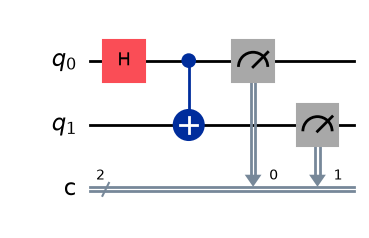

In [9]:
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])

print("Original circuit:")
print(f"  depth = {qc.depth()},  gate counts = {dict(qc.count_ops())}")
qc.draw('mpl')

Transpiled for fake_manila :
  depth = 5,  gate counts = {'rz': 2, 'measure': 2, 'sx': 1, 'cx': 1}


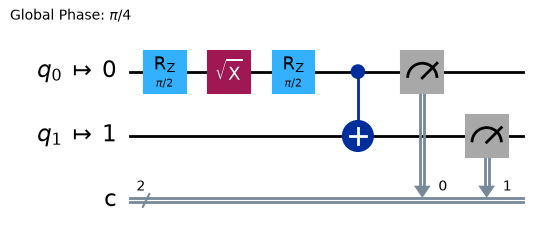

In [11]:
qc_transpiled = transpile(qc, backend, optimization_level=1)

print("Transpiled for", backend.name, ":")
print(f"  depth = {qc_transpiled.depth()},  gate counts = {dict(qc_transpiled.count_ops())}")
qc_transpiled.draw('mpl')

The single `H` gate became `rz`/`sx` rotations (the basis gates `FakeManilaV2` actually
supports), and the overall depth went up — **more depth means more time for noise to accumulate**
before measurement, which is exactly the Lab 2 §2.5 point ("this matters a lot on real quantum
hardware, where every layer accumulates noise") made concrete.

**Try It Yourself — Exercise 2.** Transpile the same `qc` with `optimization_level=3` instead of
`1`. Does the resulting depth or gate count change? (The transpiler has several optimization
passes available — higher levels try harder to simplify the circuit, at the cost of more compile
time.)

In [11]:
# Write your solution below




## 6. Running on Real Hardware

This is the step that actually needs your own account from Section 2. The pattern is: pick a
backend, transpile for it, submit via the `Sampler` primitive, then retrieve the result. **Jobs on
real hardware are queued** — depending on how busy the device is, this can take anywhere from
seconds to hours, so `job.result()` will simply wait (block) until your job finishes.

> ⚠️ **This cell needs your own live `service` and a real backend — it submits an actual job.**

In [ ]:
from qiskit_ibm_runtime import Sampler

real_backend = service.least_busy(simulator=False)
print("Using backend:", real_backend.name)

qc_t = transpile(qc, real_backend, optimization_level=1)

sampler = Sampler(mode=real_backend)
job = sampler.run([qc_t], shots=1000)
print("Job ID:", job.job_id())   # save this! you can retrieve results later even if you close the notebook

result = job.result()
real_counts = result[0].data.c.get_counts()
print("Real hardware result:", real_counts)

**Retrieving a job later.** Because real jobs can sit in a queue for a while, you don't have
to wait around — close the notebook, come back later, and retrieve the same result with the job ID
you printed above:

```python
job = service.job("paste-your-job-id-here")
result = job.result()
```

## 7. A Practice Run: Previewing What to Expect

While a real job is queued (or before you've set up an account at all), let's run the *exact same*
`Sampler` code from Section 6 against our offline `FakeManilaV2` stand-in, so we know what kind of
result to expect:

In [13]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

from qiskit_ibm_runtime import Sampler

qc_t = transpile(qc, backend, optimization_level=1)

sampler = Sampler(mode=backend)
job = sampler.run([qc_t], shots=2000)
result = job.result()
fake_counts = result[0].data.c.get_counts()

print("Fake-backend (realistic noise model) result:", fake_counts)

Fake-backend (realistic noise model) result: {'11': 917, '00': 952, '01': 53, '10': 78}


Ideal simulator:  {'11': 1024, '00': 976}
Realistic noise:  {'11': 917, '00': 952, '01': 53, '10': 78}


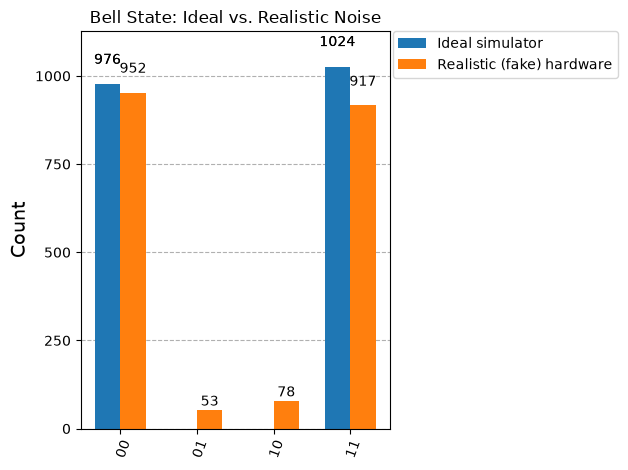

In [14]:
# Compare against the ideal simulator result for the SAME circuit
compiled_ideal = transpile(qc, simulator)
ideal_counts = simulator.run(compiled_ideal, shots=2000).result().get_counts()

print("Ideal simulator: ", ideal_counts)
print("Realistic noise: ", fake_counts)

plot_histogram([ideal_counts, fake_counts], legend=["Ideal simulator", "Realistic (fake) hardware"],
               title="Bell State: Ideal vs. Realistic Noise")

Just like the original Lab 2b observation, `01` and `10` — which should be mathematically
impossible for a perfect Bell state — show up as a **small but real** fraction of outcomes. This
isn't a bug or bad luck; it's the T1/T2 decay, CX gate error, and readout error from Section 4,
all acting on this specific circuit.

## 8. Why the Noise Happens

Tying each `01`/`10` outcome back to a concrete physical cause:

- **Decoherence (T1/T2)**: every gate and every qubit-wire takes real time. If a qubit sits idle
  (waiting for other qubits' gates to finish) for too large a fraction of its T1 or T2, it can
  decay or dephase before it's even measured.
- **Gate error**: the CX gate itself has some probability (Section 4's `cx_props[...].error`,
  typically ~0.5–1%) of applying slightly the wrong operation.
- **Readout error**: even a perfectly-prepared qubit can be *measured* incorrectly — the detector
  itself isn't perfect.
- **Crosstalk**: operating one qubit can slightly disturb its physical neighbors, especially
  relevant once circuits use many qubits at once (Section 10).

None of these are modeling mistakes — they're physical realities of today's hardware, and they're
a major part of why current quantum computing is still called the "NISQ era."

**Try It Yourself — Exercise 3.** Look back at the CX error you printed in Section 4 for your
backend's edges. With a single CX gate at roughly that error rate and 2000 shots, roughly how many
shots would you expect to land on a "wrong" outcome from that gate error *alone*? Compare that
rough estimate to the actual `01`+`10` count you got in Section 7 — are they in the same ballpark?

In [15]:
# Write your solution below




## 9. A Taste of Error Mitigation

You can't eliminate hardware noise, but Qiskit Runtime offers a few knobs that can **suppress**
some of it:

- **Dynamical decoupling**: inserts extra, carefully-timed pulses into idle qubit periods, which
  helps average out some dephasing noise while a qubit is waiting around.
- **Twirling**: randomizes *how* a gate is implemented (equivalent operations that do the same
  thing) across many shots, which tends to turn structured, biased errors into unbiased random
  noise — easier to average away.

> ⚠️ **Honesty check:** these options only change anything on **real hardware** (or IBM's cloud
> noise models) — running them against a local `FakeBackendV2` like ours triggers a Qiskit warning
> ("have no effect in local testing mode") and is silently ignored. We'll still run the comparison
> below so you can see the *code pattern* for turning these on, but don't expect the two results to
> look meaningfully different here — any gap you see is just ordinary shot noise, not mitigation at
> work. The real test is Section 10, Step 5, on actual hardware.

In [16]:
qc_ghz4 = QuantumCircuit(4, 4)
qc_ghz4.h(0)
qc_ghz4.cx(0, 1)
qc_ghz4.cx(1, 2)
qc_ghz4.cx(2, 3)
qc_ghz4.measure(range(4), range(4))

qc_ghz4_t = transpile(qc_ghz4, backend, optimization_level=1)

# Without mitigation
sampler_plain = Sampler(mode=backend)
counts_plain = sampler_plain.run([qc_ghz4_t], shots=2000).result()[0].data.c.get_counts()

# With dynamical decoupling + twirling enabled
sampler_dd = Sampler(mode=backend)
sampler_dd.options.dynamical_decoupling.enable = True
sampler_dd.options.twirling.enable_gates = True
sampler_dd.options.twirling.enable_measure = True
counts_dd = sampler_dd.run([qc_ghz4_t], shots=2000).result()[0].data.c.get_counts()

def intended_fraction(counts):
    total = sum(counts.values())
    intended = counts.get('0000', 0) + counts.get('1111', 0)
    return 100 * intended / total

print("Plain            :", counts_plain)
print(f"  -> fraction in intended states (0000/1111): {intended_fraction(counts_plain):.1f}%")
print()
print("DD + twirling     :", counts_dd)
print(f"  -> fraction in intended states (0000/1111): {intended_fraction(counts_dd):.1f}%")

Plain            : {'0100': 82, '1111': 779, '0000': 881, '0011': 5, '1110': 36, '0010': 17, '0110': 6, '1101': 22, '1011': 107, '0001': 23, '1001': 6, '0111': 19, '1010': 5, '1100': 2, '1000': 7, '0101': 3}
  -> fraction in intended states (0000/1111): 83.0%

DD + twirling     : {'1111': 763, '0000': 880, '1011': 129, '0111': 20, '1110': 54, '0100': 67, '0010': 16, '0001': 21, '1101': 23, '1000': 10, '1001': 3, '1100': 4, '0011': 3, '1010': 4, '0101': 2, '0110': 1}
  -> fraction in intended states (0000/1111): 82.2%


/home/rmarasiganjr/anaconda3/lib/python3.12/site-packages/qiskit_ibm_runtime/fake_provider/local_service.py:290: UserWarning: Options {'dynamical_decoupling': {'enable': True}, 'twirling': {'enable_gates': True, 'enable_measure': True}} have no effect in local testing mode.
  warnings.warn(f"Options {options_copy} have no effect in local testing mode.")


As predicted: the two "fraction in intended states" numbers above are close — within a percentage
point or two — because, as the warning Qiskit printed confirms, `dynamical_decoupling` and
`twirling` had nothing to act on in local testing mode. The code pattern (`sampler.options....`)
is exactly correct and exactly what you'd use on real hardware; it's the *backend*, not the code,
that determines whether it does anything.

## 10. Guided Lab: Depth vs. Noise

This is the lab proper. We'll reuse Lab 2's GHZ-3 and GHZ-4 circuits **exactly as built there** —
no new circuits to design — and measure something Lab 2 could only predict in theory: as circuit
depth grows, how much *more* noise creeps in?

### Step 1 — Build GHZ-3 and GHZ-4 (from Lab 2, Part 1 Tasks 1–2)

In [17]:
qc_ghz3 = QuantumCircuit(3, 3)
qc_ghz3.h(0)
qc_ghz3.cx(0, 1)
qc_ghz3.cx(1, 2)
qc_ghz3.measure(range(3), range(3))

qc_ghz3_t = transpile(qc_ghz3, backend, optimization_level=1)

print(f"GHZ-3: original depth={qc_ghz3.depth()}, transpiled depth={qc_ghz3_t.depth()}")
print(f"GHZ-4: original depth={qc_ghz4.depth()}, transpiled depth={qc_ghz4_t.depth()}")

GHZ-3: original depth=4, transpiled depth=6
GHZ-4: original depth=5, transpiled depth=7


### Step 2 — Run both on the (realistic, noisy) fake backend

In [18]:
shots = 4000

counts_ghz3 = Sampler(mode=backend).run([qc_ghz3_t], shots=shots).result()[0].data.c.get_counts()
counts_ghz4 = Sampler(mode=backend).run([qc_ghz4_t], shots=shots).result()[0].data.c.get_counts()

def intended_fraction_n(counts, n):
    total = sum(counts.values())
    intended = counts.get('0' * n, 0) + counts.get('1' * n, 0)
    return 100 * intended / total

frac3 = intended_fraction_n(counts_ghz3, 3)
frac4 = intended_fraction_n(counts_ghz4, 4)

print("GHZ-3 counts:", counts_ghz3)
print(f"  -> {frac3:.1f}% of shots landed on 000 or 111")
print()
print("GHZ-4 counts:", counts_ghz4)
print(f"  -> {frac4:.1f}% of shots landed on 0000 or 1111")

GHZ-3 counts: {'000': 1773, '011': 245, '111': 1615, '100': 136, '001': 36, '110': 93, '101': 54, '010': 48}
  -> 84.7% of shots landed on 000 or 111

GHZ-4 counts: {'0000': 1773, '1111': 1505, '0100': 150, '1101': 54, '1011': 235, '0001': 45, '1110': 99, '0011': 19, '1010': 13, '0111': 37, '0110': 5, '0010': 27, '1000': 21, '1100': 6, '0101': 3, '1001': 8}
  -> 82.0% of shots landed on 0000 or 1111


### Step 3 — Visualize the degradation

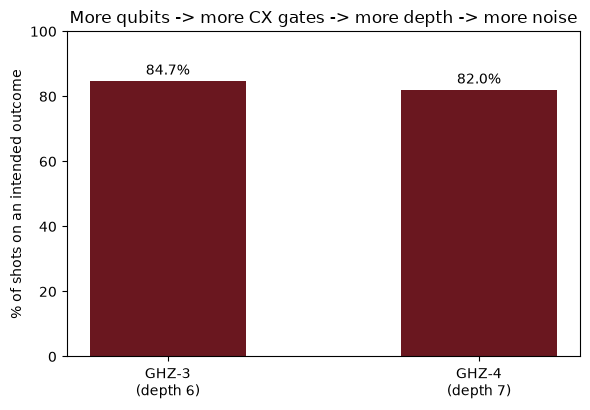

In [19]:
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.bar(['GHZ-3\n(depth %d)' % qc_ghz3_t.depth(), 'GHZ-4\n(depth %d)' % qc_ghz4_t.depth()],
       [frac3, frac4], color='#6A171F', width=0.5)
ax.set_ylabel('% of shots on an intended outcome')
ax.set_ylim(0, 100)
ax.set_title('More qubits -> more CX gates -> more depth -> more noise')
for i, v in enumerate([frac3, frac4]):
    ax.text(i, v + 2, f"{v:.1f}%", ha='center')
plt.tight_layout()
plt.show()

### Step 5 — Now for real

Everything above used the offline, realistic-but-simulated `FakeManilaV2`. Repeating this on
**real** hardware — with your own IBM Quantum account — is exactly **Task 6** in the Student Task
section near the end of this notebook, where it's combined with a side-by-side comparison chart
against the `frac3`/`frac4` predictions you just computed.

## 11. Practical Notes for Working with Real Hardware

- **Treat your API token like a password.** Never commit it, never paste it directly into a cell,
  never share a notebook that has it saved in output.
- **Queues are real.** A busy backend can mean minutes to hours of wait per job — plan submissions
  ahead of a deadline, don't start at the last minute.
- **Shots cost queue time.** More shots = more precise estimates (Lab 2 §8.6), but also a longer
  job. 1,000–4,000 shots is plenty for everything in this lab.
- **Save your job IDs.** `job.job_id()` lets you retrieve a result later via `service.job(id)`,
  even after restarting your notebook or if your session disconnects mid-queue.
- **Results aren't perfectly reproducible.** Unlike the simulator, a backend's calibration drifts
  day to day — rerunning the exact same circuit tomorrow can give slightly different noise
  characteristics.
- **Free-tier access has limits.** Check your account's current monthly quota before planning a
  large batch of jobs.

## 🧪 Student Task: Submit Your Own Circuit to Real Hardware

### 🎯 Objective

Everything up to this point used `FakeManilaV2` — a realistic, offline, verified stand-in — so
this entire notebook would run without anyone's live credentials. This task is where you close
that gap: using **your own** IBM Quantum account, repeat the core workflow (read calibration data
→ transpile → submit → compare) against **real** hardware, and find out how well our offline
preview actually predicted it.

Each task below tells you exactly which earlier section to adapt — you are not designing anything
new, just pointing the same code at a real backend instead of a fake one.

### 🧩 Task 1 — Set Up and Verify Access

Complete Section 2 with your own valid `ibm-key.txt`, then run Section 3's backend-listing cell
for real. Record: which backend did `service.least_busy(simulator=False)` pick for you, and how
many qubits does it have?

In [ ]:
# Task 1 -- run this with your own live `service` from Section 2
real_backend = service.least_busy(simulator=False)
print("My real backend:", real_backend.name, "-", real_backend.num_qubits, "qubits")

### 🧩 Task 2 — Read Your Backend's Calibration Data

Adapt Section 4's code to your `real_backend` instead of `backend`. Print T1/T2 for at least 3
qubits and CX error for at least 2 connected pairs. Identify the "best" pair you checked (longest
T1/T2, lowest CX error) and the "worst."

In [21]:
# Task 2 -- adapt Section 4's calibration-reading code to `real_backend`




### 🧩 Task 3 — Transpile for Your Backend

Transpile `qc` (the Bell-state circuit from Section 5) for `real_backend`. Record the transpiled
depth and gate counts, and compare them to the `FakeManilaV2` numbers from Section 5 — are they
similar, or does your real backend's native gate set/connectivity produce something noticeably
different?

In [22]:
# Task 3 -- transpile qc for real_backend and print depth/gate counts




### 🧩 Task 4 — Submit and Retrieve

Run Section 6's submission cell for real, targeting `real_backend`. **Print and save the job ID**
before anything else — if the queue is long, you can come back later and retrieve the same result
with `service.job("your-id")` rather than resubmitting.

In [ ]:
# Task 4 -- submit qc to real_backend via Sampler, print the job ID, then get the result
qc_real_t = transpile(qc, real_backend, optimization_level=1)

sampler = Sampler(mode=real_backend)
job = sampler.run([qc_real_t], shots=1000)
print("Job ID:", job.job_id())   # save this!

result = job.result()
real_counts = result[0].data.c.get_counts()
print("My real hardware result:", real_counts)

### 🧩 Task 5 — Three-Way Comparison

Plot `ideal_counts` (Section 7), `fake_counts` (Section 7), and your own `real_counts` (Task 4)
together. Which was closer to your real result — the ideal simulator, or the offline
`FakeManilaV2` preview? Compare their `01`+`10` "leakage" counts specifically, not just a visual
impression.

In [ ]:
# Task 5 -- three-way comparison
plot_histogram([ideal_counts, fake_counts, real_counts],
               legend=["Ideal simulator", "Offline preview (FakeManilaV2)", "My real hardware"],
               title="Bell State: Ideal vs. Offline Preview vs. Real Hardware")

for name, counts in [("Ideal", ideal_counts), ("Offline preview", fake_counts), ("My real hardware", real_counts)]:
    total = sum(counts.values())
    leakage = counts.get('01', 0) + counts.get('10', 0)
    print(f"{name:<20}: {100*leakage/total:.1f}% leakage into 01/10")

### 🧩 Task 6 — Depth vs. Noise, For Real

Repeat Section 10's Step 5: run `qc_ghz3` and `qc_ghz4` on `real_backend`, compute the real
intended-outcome percentages, and compare them to the offline predictions `frac3`/`frac4` from
Section 10.

In [ ]:
# Task 6 -- GHZ-3 and GHZ-4 on real hardware
qc_ghz3_real_t = transpile(qc_ghz3, real_backend, optimization_level=1)
qc_ghz4_real_t = transpile(qc_ghz4, real_backend, optimization_level=1)

real_counts_ghz3 = Sampler(mode=real_backend).run([qc_ghz3_real_t], shots=4000).result()[0].data.c.get_counts()
real_counts_ghz4 = Sampler(mode=real_backend).run([qc_ghz4_real_t], shots=4000).result()[0].data.c.get_counts()

real_frac3 = intended_fraction_n(real_counts_ghz3, 3)
real_frac4 = intended_fraction_n(real_counts_ghz4, 4)

print(f"REAL GHZ-3: {real_frac3:.1f}% intended   (offline preview predicted {frac3:.1f}%)")
print(f"REAL GHZ-4: {real_frac4:.1f}% intended   (offline preview predicted {frac4:.1f}%)")

fig, ax = plt.subplots(figsize=(7, 4.2))
x = ['GHZ-3', 'GHZ-4']
width = 0.35
ax.bar([i - width/2 for i in range(2)], [frac3, frac4], width, label='Offline preview', color='#C9C9C9')
ax.bar([i + width/2 for i in range(2)], [real_frac3, real_frac4], width, label='My real hardware', color='#6A171F')
ax.set_xticks(range(2))
ax.set_xticklabels(x)
ax.set_ylabel('% of shots on an intended outcome')
ax.set_ylim(0, 100)
ax.legend()
ax.set_title('Offline preview vs. my real hardware')
plt.tight_layout()
plt.show()

### 🧠 Conclusion Requirement

Write a short conclusion (5–10 sentences), based on **your own results**, covering:

- How close the offline `FakeManilaV2` preview was to your real backend's actual behavior, and
  which number (leakage %, intended-outcome %, transpiled depth, …) it predicted *least*
  accurately.
- Whether the "more depth → more noise" pattern from Section 10 held up on real hardware the same
  way it did in the offline preview.
- One thing about working with real quantum hardware that surprised you, now that you've actually
  run on it yourself.

👉 Base this on what you actually observed — not on what you expected to see.

### 📦 Submission Requirements

Submit:
- Completed, executed code for Tasks 1–6 (real outputs, not the unexecuted template cells from
  earlier in this notebook)
- Your job ID(s) from Tasks 4 and 6
- The three-way comparison histogram (Task 5) and its leakage percentages
- The offline-vs-real comparison chart (Task 6)
- Your written conclusion

> 📌 **Note:** Because queue times, backend choice, and day-to-day calibration drift all vary,
> your numbers will not match anyone else's exactly — including the specific numbers shown earlier
> in this notebook. That's expected, not a mistake.

## Summary

| Concept | Key takeaway |
|---|---|
| NISQ hardware | Real quantum computers are noisy; the simulator is the ideal case they approximate |
| T1 / T2 | How long a qubit holds its state / phase before decaying or dephasing |
| Gate error | Two-qubit gates (CX) are far noisier than single-qubit gates |
| Readout error | Measurement itself can misreport a qubit's state |
| Coupling map | Physical qubits can only interact with certain neighbors directly |
| Transpilation | Rewrites a circuit into a backend's native gates + respects its coupling map |
| `Sampler` primitive | The Runtime interface for submitting circuits to a backend and getting counts back |
| Job ID | Lets you retrieve a real-hardware result later, since jobs are queued, not instant |
| Depth vs. noise | More qubits/gates -> more depth -> more accumulated error (confirmed in Section 10) |
| Error mitigation | Dynamical decoupling and twirling can suppress, not eliminate, some noise sources |

**Where this goes next:** everything here generalizes to any circuit from Lab 2 — Bell states,
larger GHZ states, or circuits of your own design. The pattern is always the same: build it once
with "ideal" Qiskit gates, then `transpile()` it for whichever backend (fake or real) you're
targeting, and submit through `Sampler`. The gap between your Section 7 "preview" numbers and your
Section 10 "real hardware" numbers *is* the current state of quantum computing — and shrinking
that gap is exactly what the whole field is working on.